# 11 注文バスケットと商品の同時購入

10店舗・2022〜2024年の注文明細を全件使い、会計 ID ごとの商品集合を作る。同じ会計で同一商品が追加注文された場合も、同時購入の判定では1商品として数える。店舗ごと・年ごとに疎行列を集計するため ZIP 展開や全明細の同時メモリ保持は不要。

共起、条件付き割合、lift は観測上の関連。セット商品、価格、曜日、客層、販売期間などに影響され、因果や組み合わせの施策効果は示さない。2025年同日の注文は未観測。

In [1]:
from pathlib import Path
import zipfile,io
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from scipy.sparse import coo_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
ROOT=Path.cwd()
if not (ROOT/'input').is_dir(): ROOT=ROOT.parent
assert (ROOT/'input').is_dir()
INPUT=ROOT/'input';sns.set_theme(style='whitegrid');pd.options.display.float_format='{:,.4f}'.format
menus=pd.read_csv(INPUT/'menus.csv').sort_values('item_id').reset_index(drop=True)
item_ids=menus.item_id.tolist();item_map={item:i for i,item in enumerate(item_ids)}
store_ids=pd.read_csv(INPUT/'stores.csv').store_id.tolist()
print('店舗数:',len(store_ids),'商品数:',len(item_ids))

店舗数: 10 商品数: 84


## 全注文の疎行列による集計
会計×商品の二値行列を店舗・年ごとに作り、転置行列との積で全ペアの共起会計数を算出する。来店ログの着席会計を単位とする。

In [2]:
n_items=len(item_ids)
cooccurrence=np.zeros((n_items,n_items),dtype=np.int64)
co_by_year={year:np.zeros((n_items,n_items),dtype=np.int64) for year in [2022,2023,2024]}
orders_by_year={year:0 for year in [2022,2023,2024]};basket_summaries=[]
with zipfile.ZipFile(INPUT/'logs.zip') as z:
    for sid in store_ids:
        with z.open(f'logs/{sid}/order_items.parquet') as f:
            order=pq.read_table(io.BytesIO(f.read()),columns=['order_id','date','item_id','quantity']).to_pandas()
        assert order.order_id.notna().all() and order.item_id.isin(item_ids).all()
        order['year']=order.date.dt.year
        for year,frame in order.groupby('year',observed=True):
            row,unique_orders=pd.factorize(frame.order_id,sort=False)
            col=frame.item_id.map(item_map).to_numpy(dtype=np.int64)
            matrix=coo_matrix((np.ones(len(frame),dtype=np.int64),(row,col)),shape=(len(unique_orders),n_items)).tocsr()
            matrix.data[:]=1 # 同一会計・商品の重複明細は1とする
            counts=(matrix.T@matrix).toarray()
            cooccurrence+=counts;co_by_year[int(year)]+=counts;orders_by_year[int(year)]+=len(unique_orders)
            distinct=matrix.getnnz(axis=1);qty=np.bincount(row,weights=frame.quantity.to_numpy(),minlength=len(unique_orders))
            basket_summaries.append({'store_id':sid,'year':int(year),'orders':len(unique_orders),'lines':len(frame),'distinct_items_mean':distinct.mean(),'distinct_items_median':np.median(distinct),'items_quantity_mean':qty.mean(),'single_item_orders':int((distinct==1).sum())})
        print(sid,'注文行:',len(order),'完了',flush=True)
        del order,matrix
basket=pd.DataFrame(basket_summaries)
print('全会計数:',sum(orders_by_year.values()),'年別:',orders_by_year)
print('共起対角成分の合計:',int(np.trace(cooccurrence)))
display(basket)
assert np.all(cooccurrence==cooccurrence.T) and (np.diag(cooccurrence)<=sum(orders_by_year.values())).all()

S001 注文行: 1006670 完了
S002 注文行: 866515 完了
S003 注文行: 964313 完了
S004 注文行: 1112487 完了
S005 注文行: 801335 完了
S006 注文行: 596023 完了
S007 注文行: 731885 完了
S008 注文行: 684457 完了
S009 注文行: 579569 完了
S010 注文行: 1074336 完了
全会計数: 2337482 年別: {2022: 744000, 2023: 791833, 2024: 801649}
共起対角成分の合計: 8409197


,store_id,year,orders,lines,distinct_items_mean,distinct_items_median,items_quantity_mean,single_item_orders
0,S001,2022,80970,275670,3.4016,3.0000,4.0559,8978
1,S001,2023,106358,351737,3.3041,3.0000,3.9036,13267
2,S001,2024,115411,379263,3.2831,3.0000,3.8691,14926
3,S002,2022,93577,280982,3.0011,3.0000,3.4403,14427
4,S002,2023,96721,286632,2.9618,3.0000,3.3830,15190
5,S002,2024,102734,298901,2.9078,3.0000,3.3024,16878
6,S003,2022,72392,296303,4.0884,4.0000,4.9827,4547
7,S003,2023,77902,329441,4.2240,4.0000,5.1757,4691
8,S003,2024,78587,338569,4.3025,4.0000,5.2804,4315
9,S004,2022,76528,344989,4.5019,4.0000,5.5716,4044


## 会計あたりの商品数
異なる商品の数と数量合計を区別する。各店舗年で平均会計あたりの値を示す。

,orders,distinct_items_per_order,quantity_per_order,single_item_fraction
year,,,,
2022,"744,000.0000",3.6218,4.3401,0.1034
2023,"791,833.0000",3.5870,4.2834,0.1065
2024,"801,649.0000",3.5854,4.2720,0.1081


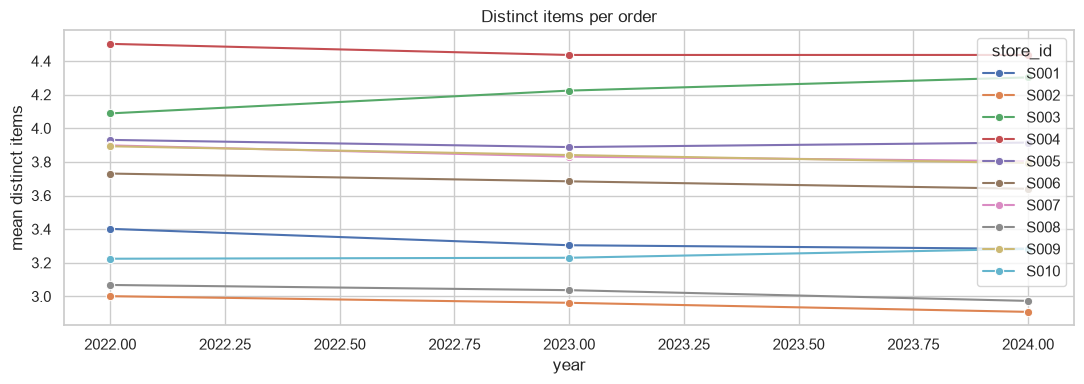

In [3]:
basket['single_item_fraction']=basket.single_item_orders/basket.orders
annual=basket.groupby('year').apply(lambda x:pd.Series({'orders':x.orders.sum(),'distinct_items_per_order':np.average(x.distinct_items_mean,weights=x.orders),'quantity_per_order':np.average(x.items_quantity_mean,weights=x.orders),'single_item_fraction':x.single_item_orders.sum()/x.orders.sum()}),include_groups=False)
display(annual)
fig,ax=plt.subplots(figsize=(11,4));sns.lineplot(data=basket,x='year',y='distinct_items_mean',hue='store_id',marker='o',ax=ax);ax.set(title='Distinct items per order',ylabel='mean distinct items');plt.tight_layout();plt.show()

## 商品ペアの共起
支持率=same-order件数÷全会計数。confidence A→B=P(B|A)。lift=P(A,B)/(P(A)P(B))。商品が同時販売されていない日も分母に含むため、特に期間限定品の lift に注意する。

In [4]:
num_orders=sum(orders_by_year.values());freq=np.diag(cooccurrence)
rows=[]
for i in range(n_items):
    for j in range(i+1,n_items):
        both=int(cooccurrence[i,j])
        if both==0: continue
        rows.append({'item_a':item_ids[i],'item_b':item_ids[j],'count':both,'support':both/num_orders,'confidence_a_to_b':both/freq[i],'confidence_b_to_a':both/freq[j],'lift':both*num_orders/(freq[i]*freq[j]),'count_a':int(freq[i]),'count_b':int(freq[j])})
pairs=pd.DataFrame(rows)
item_info=menus[['item_id','item_name','category','menu_type']]
pairs=(pairs.merge(item_info.rename(columns={'item_id':'item_a','item_name':'name_a','category':'category_a','menu_type':'type_a'}),on='item_a',validate='many_to_one')
       .merge(item_info.rename(columns={'item_id':'item_b','item_name':'name_b','category':'category_b','menu_type':'type_b'}),on='item_b',validate='many_to_one'))
cols=['item_a','name_a','item_b','name_b','count','support','confidence_a_to_b','confidence_b_to_a','lift']
print('全会計において共起が1件以上のペア:',len(pairs))
print('共起件数上位:');display(pairs.nlargest(20,'count')[cols])
print('共起1,000件以上のペアに限る lift 上位:');display(pairs[pairs['count']>=1000].nlargest(20,'lift')[cols])

全会計において共起が1件以上のペア: 3282
共起件数上位:
共起1,000件以上のペアに限る lift 上位:


,item_a,name_a,item_b,name_b,count,support,confidence_a_to_b,confidence_b_to_a,lift
39,M002,Drink Bar (With Main),M007,Cheese In Hamburg,190572,0.0815,0.1051,0.8736,1.1262
44,M002,Drink Bar (With Main),M012,Gratin Doria,188790,0.0808,0.1041,0.8790,1.1332
35,M002,Drink Bar (With Main),M003,Classic Hamburg Steak,185576,0.0794,0.1023,0.8689,1.1201
38,M002,Drink Bar (With Main),M006,Beef Curry,182466,0.0781,0.1006,0.8528,1.0994
41,M002,Drink Bar (With Main),M009,Seafood Cream Pasta,181513,0.0777,0.1001,0.8731,1.1256
42,M002,Drink Bar (With Main),M010,Stewed Beef Omelet Rice,180018,0.0770,0.0993,0.8722,1.1244
48,M002,Drink Bar (With Main),M016,Avocado Taco Rice,176148,0.0754,0.0971,0.8676,1.1185
40,M002,Drink Bar (With Main),M008,Miso Butter Chicken,175664,0.0752,0.0969,0.8598,1.1085
46,M002,Drink Bar (With Main),M014,Shrimp Pilaf,174741,0.0748,0.0964,0.8666,1.1172
36,M002,Drink Bar (With Main),M004,Chicken Grill Plate,171780,0.0735,0.0947,0.8524,1.0988


,item_a,name_a,item_b,name_b,count,support,confidence_a_to_b,confidence_b_to_a,lift
3280,M082,Anime Hero Fire Burger,M084,Anime Hero Side Star Plate,2402,0.0010,0.1063,0.2764,28.6071
3279,M082,Anime Hero Fire Burger,M083,Anime Hero Prism Parfait,1120,0.0005,0.0496,0.2228,23.0558
3211,M067,Mango Coconut Parfait,M069,Salt Lemon Chicken Basket,2120,0.0009,0.0962,0.0603,6.3991
3200,M066,Spicy Tex Mex Burger Plate,M069,Salt Lemon Chicken Basket,7455,0.0032,0.0868,0.2121,5.7708
20,M001,Drink Bar (Single),M056,Coffee Jelly,3724,0.0016,0.0997,0.0913,5.7145
23,M001,Drink Bar (Single),M059,Tiramisu Cup,3843,0.0016,0.1029,0.0894,5.5973
22,M001,Drink Bar (Single),M058,Cream Anmitsu,3487,0.0015,0.0934,0.0888,5.5576
14,M001,Drink Bar (Single),M050,Cheese Cake,3844,0.0016,0.1029,0.0886,5.5479
17,M001,Drink Bar (Single),M053,Custard Pudding,3533,0.0015,0.0946,0.0880,5.5110
18,M001,Drink Bar (Single),M054,Mont Blanc,4013,0.0017,0.1075,0.0880,5.5097


## 上位ペアの年別推移
全期間の共起件数上位12ペアを年別に分ける。会計全体を分母にしており、販売期間・対象店舗・商品構成の違いを含む。

year,2022,2023,2024
pair,,,
M002 × M003,0.0802,0.0792,0.0788
M002 × M004,0.0742,0.0735,0.0728
M002 × M006,0.0785,0.0777,0.0780
M002 × M007,0.0827,0.0814,0.0805
M002 × M008,0.0760,0.0753,0.0742
M002 × M009,0.0781,0.0779,0.0770
M002 × M010,0.0780,0.0766,0.0765
M002 × M011,0.0720,0.0713,0.0709
M002 × M012,0.0816,0.0806,0.0801


year,2022,2023,2024
pair,,,
M002 × M003,1.1185,1.1192,1.1226
M002 × M004,1.0988,1.0974,1.1002
M002 × M006,1.0969,1.0986,1.1026
M002 × M007,1.1259,1.1264,1.1260
M002 × M008,1.1063,1.1085,1.1104
M002 × M009,1.1234,1.1251,1.1281
M002 × M010,1.1248,1.1240,1.1243
M002 × M011,1.1075,1.1125,1.1120
M002 × M012,1.1284,1.1358,1.1351


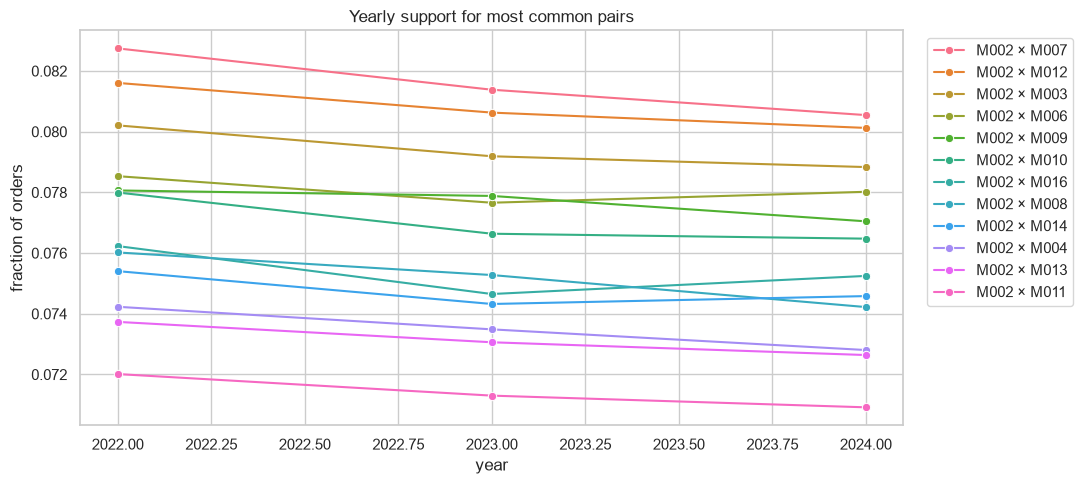

In [5]:
selected=pairs.nlargest(12,'count')
rows_year=[]
for r in selected.itertuples(index=False):
    i=item_map[r.item_a];j=item_map[r.item_b]
    for year,matrix in co_by_year.items():
        total=orders_by_year[year]; count=int(matrix[i,j]);a=int(matrix[i,i]);b=int(matrix[j,j])
        rows_year.append({'pair':r.item_a+' × '+r.item_b,'year':year,'orders':total,'both':count,'support':count/total,'lift':count*total/(a*b) if a and b else np.nan})
pair_year=pd.DataFrame(rows_year)
display(pair_year.pivot(index='pair',columns='year',values='support'))
display(pair_year.pivot(index='pair',columns='year',values='lift'))
assert np.array_equal(sum(co_by_year.values()),cooccurrence)
fig,ax=plt.subplots(figsize=(11,5));sns.lineplot(data=pair_year,x='year',y='support',hue='pair',marker='o',ax=ax);ax.set(title='Yearly support for most common pairs',ylabel='fraction of orders');ax.legend(bbox_to_anchor=(1.02,1),loc='upper left');plt.tight_layout();plt.show()

## カテゴリ間の同時購入
各ペアを1回数える商品ペア件数であり、1会計に複数ペアがある場合は同じ会計が複数回寄与する。

lift上位や共起の大小だけで需要予測上の有効性・因果を判断しない。


,cooccurring_item_pairs
category_pair,
drink_bar × main,3234810
main × side,2362143
main × main,2295490
dessert × main,1154664
drink_bar × side,979801
kids × main,687383
drink_bar × lunch,601172
dessert × drink_bar,577201
lunch × main,513841


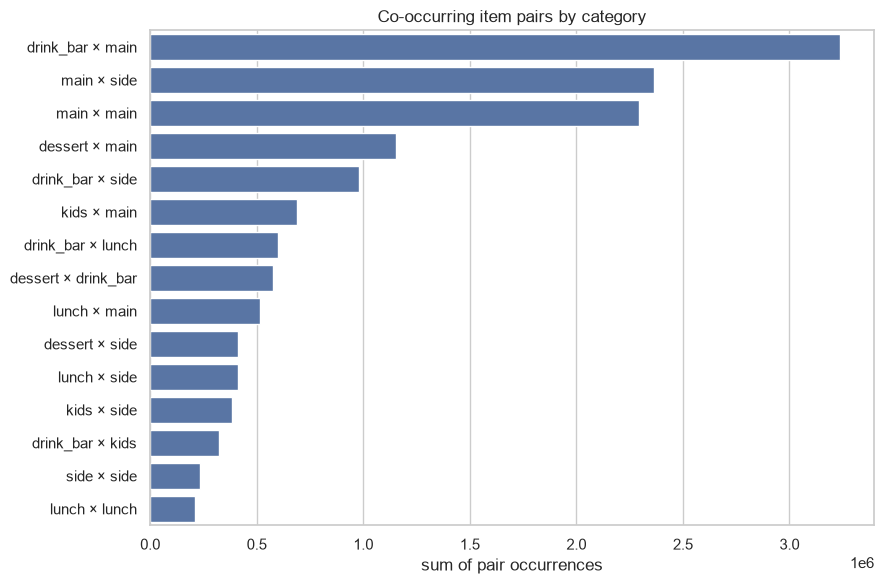

In [6]:
pairs['category_pair']=pairs.apply(lambda r:' × '.join(sorted([r.category_a,r.category_b])),axis=1)
cat=pairs.groupby('category_pair')['count'].sum().sort_values(ascending=False)
display(cat.to_frame('cooccurring_item_pairs'))
fig,ax=plt.subplots(figsize=(9,6));sns.barplot(x=cat.head(15).values,y=cat.head(15).index,ax=ax);ax.set(title='Co-occurring item pairs by category',xlabel='sum of pair occurrences',ylabel='');plt.tight_layout();plt.show()
print('lift上位や共起の大小だけで需要予測上の有効性・因果を判断しない。')

## 解釈の注意
- 同時購入は過去実績のパターン。目的の商品と同じ将来日の他商品の実際の販売数を特徴量に使うとリークする。
- バスケットの多い商品は高頻度になりやすい。件数だけでなく支持率や条件付き割合を見る。
- 期間限定商品同士の高い lift は、共通する販売期間やキャンペーンによって生じ得る。